# Free Clinic of Powhatan — A1C preliminary analysis (5.02a, all lab results)
Run locally on the clinic-approved export. **The notebook prints only aggregate counts — no names, phone numbers, or account numbers.** Saved outputs still describe a small clinic population, so keep them internal.

This is the companion to `a1c_preliminary_analysis.ipynb`. That notebook used **5.02b** (numeric-range report), which turned out to contain only A1C results ≥ 10%. This notebook uses **5.02a**, the unrestricted Lab Results Analysis Report. It contains every lab attribute (CMP, CBC, lipids, …), so the first job is to filter to the verified A1C attribute rows.

It describes; it does not diagnose diabetes, infer treatment effects, or set clinical targets. Clinical cutpoints in the settings cell are **provisional defaults taken from published ADA categories**, clearly labeled, and must be confirmed (or replaced) by the clinic before results are shared.

Run with the project's `.venv` kernel (it has pandas, numpy, matplotlib).

## 1. Imports

In [1]:
from pathlib import Path
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Chart palette (reference data-viz palette): one primary hue, muted context, ink tokens.
BLUE, BLUE_DARK, BLUE_LIGHT = "#2a78d6", "#104281", "#9ec5f4"
ORANGE = "#eb6834"
MUTED = "#a8a7a0"
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

## 2. Settings — review this cell first
**Data settings** were checked against the 5.02a file on 2026-11-14:
- UTF-16, tab-separated; data rows carry a trailing tab (handled by the loader).
- Verified A1C attributes are `Hemoglobin A1C` and `Hemoglobin A1c` (matched case-insensitively). `Est. Average Glucose` is a *derived* value inside the "with EAG" order and is **excluded**. `B-2-Glycoprotein` matches a loose "glyco" search but is an unrelated test.
- All numeric A1C values fall between 3.8 and 21.8, consistent with percent (NGSP) units rather than mmol/mol (IFCC values would be ~20–200). That is why `UNITS_CONFIRMED_PERCENT = True`; still confirm with the clinic.

**Analysis period:** the full extract span (`2023-01-01` to the export date). Section 4b confirms it against 5.02b.

**Provisional clinical cutpoints (pending clinic approval):**
| Setting | Default | Source |
|---|---|---|
| Prediabetes range | 5.7–6.4% | ADA diagnostic categories |
| Diabetes range | ≥ 6.5% | ADA diagnostic categories |
| Control threshold | < 7.0% | ADA general glycemic goal for many non-pregnant adults; individual targets vary |
| Meaningful change | ±0.5 percentage points | commonly used clinically meaningful A1C change |

A lab extract does **not** tell us who has a diabetes diagnosis. "Diabetes-range cohort" below means *patients whose first A1C in the period was ≥ 6.5%* — a lab-based proxy, not a diagnosis.

In [2]:
INPUT_FILE = Path("data/5.02a - Lab Results Analysis Report.csv")
COMPARE_FILE = Path("data/5.02b - Lab Results Analysis Report for Numeric Lab Values (1).csv")  # for date-range check
SHEET_NAME = 0
HEADER_ROW = 0
CSV_ENCODING = None            # auto-detect UTF-16 BOM, otherwise UTF-8 with BOM support
CSV_SEPARATOR = None           # auto-detect from header line

START_DATE = "2023-01-01"      # inclusive; full extract span — confirm with clinic
END_DATE = "2026-11-14"        # inclusive; export date
UNITS_CONFIRMED_PERCENT = True # values 3.8–21.8 => percent units (see markdown above)
A1C_LABELS = {"Hemoglobin A1c"}   # case-insensitive => matches "Hemoglobin A1C" and "Hemoglobin A1c"
A1C_SEARCH_PATTERN = r"a1c|hba1|glycated|glycosylated|glyco|average glucose"  # for the label audit only
ELIGIBLE_IDS_FILE = None       # optional Path("data/eligible_patients.csv") with a patient_id column

COLUMN = {
    "patient_id": "patient_acct_no",
    "date": "order_collection_performed_date",
    "attribute": "lab_attribute",
    "value": "lab_attribute_value",
    "order_name": "order_name",
    "order_status": "order_status",
}
ID_COLUMNS = None              # auto-coalesce repeated Patient Acct No columns

# ---- PROVISIONAL clinical settings (ADA-based defaults; replace with clinic-approved values) ----
PREDIABETES_THRESHOLD = 5.7
DIABETES_RANGE_THRESHOLD = 6.5
CONTROL_THRESHOLD = 7.0
CONTROL_OPERATOR = "<"
STABILITY_TOLERANCE_PP = 0.5
BASELINE_BINS = [0, 5.7, 6.5, 8.0, 10.0, np.inf]
BASELINE_LABELS = ["<5.7", "5.7–6.4", "6.5–7.9", "8.0–9.9", "≥10.0"]
FOLLOWUP_WINDOW_DAYS = 183     # "repeat test within ~6 months" for the diabetes-range cohort
REVIEW_HIGH_VALUE = 15.0       # values above this are listed for source review (kept unless excluded)
SETTINGS_ARE_PROVISIONAL = True

# ---- Duplicates and exclusions ----
COLLAPSE_IDENTICAL_DUPLICATES = True  # same patient + same day + identical value => keep one row
APPROVED_KEEP_DUPLICATE_ROWS = []     # representative source rows for conflicting same-day groups
MANUAL_EXCLUDE_ROWS = []              # clinician/data-owner-approved exclusions only
EXCLUSION_REASON = ""

OUTPUT_DIR = Path("outputs/5.02a")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SAVE_ROW_LEVEL_FILES = False   # row-level files contain account numbers and dates

EXPORT_NOTES = {
    "report": "5.02a Lab Results Analysis Report",
    "date_field": "Order Collection / Performed Date",
    "all_results": "All lab attributes; no numeric-range restriction",
    "numeric_ranges": "none (contrast: 5.02b contained only A1C >= 10)",
    "lab_status_active": "",
    "inhouse_labs": "Both (A1C rows are all InHouse Lab = No)",
    "other_filters": "",
    "cohort_definition": "Patients with >=1 matched A1C in the period; diabetes-range cohort = first A1C >= 6.5",
    "units_confirmation": "Numeric range check only (3.8-21.8); confirm with clinic",
    "duplicate_resolution": "Identical same-day copies collapsed; conflicting same-day groups set aside",
}

## 3. Load the export and inspect its structure
The eCW CSV export is UTF-16 and tab-delimited, and every data row ends with a trailing tab, so rows have one more field than the header. `index_col=False` keeps pandas from turning the first column into the index (which would shift every column one place left).

In [3]:
def normalized_name(value):
    return re.sub(r"[^a-z0-9]+", "_", str(value).strip().lower()).strip("_")

def load_export(path, verbose=True):
    if not path.exists():
        raise FileNotFoundError(f"Put the export at {path.resolve()} or edit INPUT_FILE.")
    if path.suffix.lower() in {".xlsx", ".xlsm"}:
        return pd.read_excel(path, sheet_name=SHEET_NAME, header=HEADER_ROW, dtype=str, engine="openpyxl")
    with path.open("rb") as handle:
        prefix = handle.read(4)
    encoding = CSV_ENCODING or ("utf-16" if prefix.startswith((b"\xff\xfe", b"\xfe\xff")) else "utf-8-sig")
    separator = CSV_SEPARATOR
    if separator is None:
        with path.open("r", encoding=encoding, newline="") as handle:
            lines = handle.read(65536).splitlines()
        header_line = lines[HEADER_ROW] if len(lines) > HEADER_ROW else ""
        counts = {d: header_line.count(d) for d in ("\t", ",", ";", "|")}
        separator = max(counts, key=counts.get)
        if counts[separator] == 0:
            raise ValueError("Set CSV_SEPARATOR explicitly to the file delimiter.")
    if verbose:
        print(f"{path.name}: encoding={encoding}, separator={separator!r}")
    frame = pd.read_csv(path, encoding=encoding, sep=separator, header=HEADER_ROW,
                        dtype=str, index_col=False)
    frame.columns = [normalized_name(c) for c in frame.columns]
    if frame.columns.duplicated().any():
        raise ValueError("Normalized column names collide. Rename them explicitly before proceeding.")
    return frame

raw = load_export(INPUT_FILE)
missing = [c for c in COLUMN.values() if c not in raw.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}. Check HEADER_ROW and COLUMN.")

attr_all = raw[COLUMN["attribute"]].astype("string").str.strip()
print(f"Imported rows: {len(raw):,}")
print(f"Distinct lab attributes: {attr_all.nunique():,}   distinct orders: {raw[COLUMN['order_name']].nunique():,}")
print(f"Distinct patients (any lab): {raw[COLUMN['patient_id']].nunique():,}")
print("Normalized columns:", raw.columns.tolist())
print("\nMost common lab attributes (A1C is a small slice of this export):")
display(attr_all.value_counts().head(12).rename_axis("lab_attribute").to_frame("rows"))

5.02a - Lab Results Analysis Report.csv: encoding=utf-16, separator='\t'
Imported rows: 55,364
Distinct lab attributes: 466   distinct orders: 270
Distinct patients (any lab): 596
Normalized columns: ['patient_acct_no', 'none', 'none_1', 'none_2', 'practice_name', 'encounter_date', 'order_collection_performed_date', 'appointment_facility_name', 'appointment_facility_pos', 'patient_acct_no_1', 'patient_name', 'actual_fasting', 'order_priority', 'order_name', 'order_status', 'approval_required', 'inhouse_lab', 'lab_attribute', 'lab_attribute_value', 'order_result', 'aoe_question', 'aoe_answer', 'aoe_lab_company_id', 'aoe_lab_company_name', 'count_distinct_patient_acct_no', 'count_distinct_patient_acct_no_1', 'count_distinct_patient_acct_no_2', 'count_distinct_patient_acct_no_3']

Most common lab attributes (A1C is a small slice of this export):


,rows
lab_attribute,
BUN,1383
Triglycerides,1220
Hemoglobin,1161
GLUCOSE,1139
WBC,1131
Hematocrit,1129
MCV,1129
Potassium,1061
Creatinine,1057


## 4. Filter to A1C rows
### 4a. Label audit
A loose search over attribute **and** order names shows every candidate, so the exact-match list in `A1C_LABELS` can be checked. Only rows whose *Lab Attribute* exactly matches a verified label (trimmed, case-insensitive) are kept — a loose search for "hemoglobin" would pull in the CBC hemoglobin test, and the "with EAG" order also contains an *Est. Average Glucose* row that is derived from the A1C, not a separate measurement.

In [4]:
order_all = raw[COLUMN["order_name"]].astype("string").str.strip()
candidate = (attr_all.str.contains(A1C_SEARCH_PATTERN, case=False, na=False)
             | order_all.str.contains(A1C_SEARCH_PATTERN, case=False, na=False))
labels = {x.strip().casefold() for x in A1C_LABELS}
selected = attr_all.str.casefold().isin(labels).fillna(False)

label_audit = (pd.DataFrame({"lab_attribute": attr_all[candidate], "order_name": order_all[candidate]})
               .value_counts().rename("rows").reset_index())
label_audit["kept_as_A1C"] = label_audit["lab_attribute"].str.casefold().isin(labels)
display(label_audit.sort_values(["kept_as_A1C", "rows"], ascending=[False, False]).reset_index(drop=True))
print(f"Rows kept as A1C: {int(selected.sum()):,} of {len(raw):,} report rows "
      f"({100 * selected.mean():.1f}%)")

,lab_attribute,order_name,rows,kept_as_A1C
0,Hemoglobin A1C,Hemoglobin A1C with EAG,853,True
1,Hemoglobin A1c,Hemoglobin A1c,250,True
2,Hemoglobin A1C,Hemoglobin A1C,44,True
3,Est. Average Glucose,Hemoglobin A1C with EAG,841,False
4,B-2-Glycoprotein IgM,Beta-2-Glycoprotein Abs,1,False
5,B-2-Glycoprotein IgG,Beta-2-Glycoprotein Abs,1,False


Rows kept as A1C: 1,147 of 55,364 report rows (2.1%)


### 4b. Build the A1C working table
Repeated Patient Acct No columns are coalesced within each row; conflicts are flagged. Comparator or malformed results such as `>14.0`, `6.3.` or `Clotted sample` are **not** coerced — they go to the review log.

In [5]:
def clean_id(series):
    return (series.astype("string").str.strip()
            .str.replace(r"\.0$", "", regex=True).replace("", pd.NA))

id_columns = ID_COLUMNS or [
    c for c in raw.columns
    if c == COLUMN["patient_id"] or re.fullmatch(re.escape(COLUMN["patient_id"]) + r"_\d+", c)
]
ids = pd.concat([clean_id(raw[c]).rename(c) for c in id_columns], axis=1)

work = pd.DataFrame({
    "source_row": np.arange(1, len(raw) + 1),
    "patient_id": ids.bfill(axis=1).iloc[:, 0],
    "id_conflict": ids.nunique(axis=1, dropna=True).gt(1),
    "date_text": raw[COLUMN["date"]].astype("string").str.strip(),
    "attribute": attr_all,
    "order_name": order_all,
    "order_status": raw[COLUMN["order_status"]].astype("string").str.strip(),
    "value_text": raw[COLUMN["value"]].astype("string").str.strip(),
})
work = work[selected.to_numpy()].copy()
if work.empty:
    raise ValueError("No verified A1C labels matched. Review the label audit and A1C_LABELS.")
work["date"] = pd.to_datetime(work["date_text"], format="mixed", errors="coerce").dt.normalize()
number_pattern = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)\s*%?"
plain_numeric = work["value_text"].str.fullmatch(number_pattern, na=False)
work["a1c"] = pd.to_numeric(
    work["value_text"].where(plain_numeric).str.replace("%", "", regex=False).str.strip(),
    errors="coerce")

eligible_ids = None
if ELIGIBLE_IDS_FILE is not None:
    eligible_ids = set(clean_id(pd.read_csv(ELIGIBLE_IDS_FILE, dtype=str)["patient_id"]).dropna())
    work = work[work["patient_id"].isin(eligible_ids)].copy()
scope = ("Clinic-defined eligible-patient list" if eligible_ids is not None
         else "Patients with >=1 matched A1C in this export; diabetes diagnosis not known from labs")
print("Scope:", scope)
print(f"A1C rows: {len(work):,}   patients: {work['patient_id'].nunique():,}")
print("Order status of A1C rows:", work["order_status"].value_counts().to_dict())
numeric = work["a1c"].dropna()
print(f"Numeric A1C values: {len(numeric):,}; range {numeric.min()}–{numeric.max()}, median {numeric.median()}")
if UNITS_CONFIRMED_PERCENT and not numeric.between(2, 25).all():
    print("WARNING: some numeric values fall outside 2–25; re-check units before proceeding.")

Scope: Patients with >=1 matched A1C in this export; diabetes diagnosis not known from labs
A1C rows: 1,147   patients: 520
Order status of A1C rows: {'Reviewed': 1141, 'Open': 6}
Numeric A1C values: 1,143; range 3.8–21.8, median 5.7


### 4c. Confirm the date range against 5.02b, and reconcile the two reports
5.02b ("Numeric Lab Values") was run with a forced numeric range. If 5.02a is the unrestricted version of the same query, every 5.02b A1C result should appear in 5.02a, and the date coverage should match.

In [6]:
def a1c_summary(frame, label):
    a = frame[frame[COLUMN["attribute"]].astype("string").str.strip().str.casefold().isin(labels).fillna(False)]
    d = pd.to_datetime(a[COLUMN["date"]], errors="coerce")
    v = pd.to_numeric(a[COLUMN["value"]].str.strip(), errors="coerce")
    whole = pd.to_datetime(frame[COLUMN["date"]], errors="coerce")
    return a, pd.Series({
        "A1C rows": len(a),
        "patients with A1C": a[COLUMN["patient_id"]].nunique(),
        "first A1C collection date": d.min().date(),
        "last A1C collection date": d.max().date(),
        "first collection date (any lab)": whole.min().date(),
        "last collection date (any lab)": whole.max().date(),
        "lowest numeric A1C": v.min(),
        "highest numeric A1C": v.max(),
    }, name=label)

a_a1c, a_sum = a1c_summary(raw, "5.02a (this notebook)")
if COMPARE_FILE.exists():
    raw_b = load_export(COMPARE_FILE, verbose=False)
    b_a1c, b_sum = a1c_summary(raw_b, "5.02b (numeric-range report)")
    date_check = pd.concat([a_sum, b_sum], axis=1)
    display(date_check)

    key_cols = [COLUMN["patient_id"], COLUMN["date"], COLUMN["value"]]
    key = lambda f: set(map(tuple, f[key_cols].apply(lambda s: s.str.strip()).to_numpy()))
    b_keys, a_keys = key(b_a1c), key(a_a1c)
    a_vals = pd.to_numeric(a_a1c[COLUMN["value"]].str.strip(), errors="coerce")
    a_dates = pd.to_datetime(a_a1c[COLUMN["date"]])
    b_last = pd.Timestamp(b_sum["last A1C collection date"])
    a_ge10_keys = key(a_a1c[a_vals.ge(10) & a_dates.le(b_last)])
    print(f"Distinct 5.02b A1C results (patient, date, value) also present in 5.02a: "
          f"{len(b_keys & a_keys)} of {len(b_keys)}  (5.02b has {len(b_a1c)} rows; the rest are repeated rows)")
    print(f"Distinct 5.02a A1C results >= 10% up to 5.02b's last date: {len(a_ge10_keys)}; "
          f"missing from 5.02b: {len(a_ge10_keys - b_keys)} "
          f"(values: {sorted(float(k[2]) for k in a_ge10_keys - b_keys)} — consistent with a 5.02b upper range limit)")
    print(f"Distinct 5.02a A1C results >= 10% after 5.02b's last date: "
          f"{len(key(a_a1c[a_vals.ge(10) & a_dates.gt(b_last)]))}")
    starts_same_year = a_sum["first A1C collection date"].year == b_sum["first A1C collection date"].year
    print("\nDate range: both reports begin in", a_sum["first A1C collection date"].year,
          "and end in", a_sum["last A1C collection date"].year, "— same multi-year window." if starts_same_year else "")
    print(f"5.02a extends {(b_sum['first A1C collection date'] - a_sum['first A1C collection date']).days} days earlier and "
          f"{(a_sum['last A1C collection date'] - b_sum['last A1C collection date']).days} days later, because 5.02b only "
          "kept results >= 10%; its first/last dates are simply the first/last *high* results.")
else:
    display(a_sum.to_frame())
    print("COMPARE_FILE not found; skipped 5.02b comparison.")

,5.02a (this notebook),5.02b (numeric-range report)
A1C rows,1147,68
patients with A1C,520,30
first A1C collection date,2023-01-05,2023-01-19
last A1C collection date,2026-11-12,2026-09-28
first collection date (any lab),2023-01-05,2023-01-19
last collection date (any lab),2026-11-12,2026-09-28
lowest numeric A1C,3.8,10.0
highest numeric A1C,21.8,15.8


Distinct 5.02b A1C results (patient, date, value) also present in 5.02a: 65 of 65  (5.02b has 68 rows; the rest are repeated rows)
Distinct 5.02a A1C results >= 10% up to 5.02b's last date: 66; missing from 5.02b: 1 (values: [21.8] — consistent with a 5.02b upper range limit)
Distinct 5.02a A1C results >= 10% after 5.02b's last date: 0

Date range: both reports begin in 2023 and end in 2026 — same multi-year window.
5.02a extends 14 days earlier and 45 days later, because 5.02b only kept results >= 10%; its first/last dates are simply the first/last *high* results.


## 5. Audit missing data, dates, and duplicates
The 0–100 check is a mathematical percent-scale check, not a clinical outlier rule. Values above `REVIEW_HIGH_VALUE` are **listed for review but kept**.

Same-day groups: when a patient has several A1C rows on one date with the **identical** value (typically the same result filed twice), one copy is kept (`COLLAPSE_IDENTICAL_DUPLICATES`). Same-day groups with **different** values are set aside until a representative row is approved.

In [7]:
start, end = pd.Timestamp(START_DATE).normalize(), pd.Timestamp(END_DATE).normalize()
if not UNITS_CONFIRMED_PERCENT:
    raise ValueError("Confirm consistent percent units, then set UNITS_CONFIRMED_PERCENT=True.")
if start > end:
    raise ValueError("START_DATE must be no later than END_DATE.")
if MANUAL_EXCLUDE_ROWS and not EXCLUSION_REASON.strip():
    raise ValueError("Document EXCLUSION_REASON for manual exclusions.")

flags = pd.DataFrame(index=work.index)
flags["missing_id"] = work["patient_id"].isna()
flags["conflicting_id_columns"] = work["id_conflict"]
flags["missing_or_invalid_date"] = work["date"].isna()
flags["missing_or_non_plain_numeric_result"] = work["a1c"].isna()
flags["outside_analysis_period"] = work["date"].notna() & ~work["date"].between(start, end)
flags["outside_percent_scale"] = work["a1c"].notna() & ~work["a1c"].between(0, 100)
flags["manual_exclusion"] = work["source_row"].isin(MANUAL_EXCLUDE_ROWS)

valid_mask = ~flags.any(axis=1)
valid = work.loc[valid_mask].sort_values(["patient_id", "date", "source_row"])
grp = valid.groupby(["patient_id", "date"])["a1c"]
group_size, group_values = grp.transform("size"), grp.transform("nunique")
identical_group = group_size.gt(1) & group_values.eq(1)
conflicting_group = group_size.gt(1) & group_values.gt(1)
is_later_copy = valid.duplicated(["patient_id", "date"], keep="first")

flags["identical_same_day_copy"] = False
flags["conflicting_same_day_pending"] = False
if COLLAPSE_IDENTICAL_DUPLICATES:
    flags.loc[valid.index[identical_group & is_later_copy], "identical_same_day_copy"] = True
else:
    conflicting_group = conflicting_group | identical_group
pending = conflicting_group & ~valid["source_row"].isin(APPROVED_KEEP_DUPLICATE_ROWS)
flags.loc[valid.index[pending], "conflicting_same_day_pending"] = True

clean = work.loc[~flags.any(axis=1)].copy().sort_values(["patient_id", "date", "source_row"])
if clean.duplicated(["patient_id", "date"]).any():
    raise ValueError("More than one retained result for a patient/date. Approve one representative.")

review_log = work[["source_row", "patient_id", "date_text", "attribute", "value_text"]].join(flags)
review_log = review_log.loc[flags.any(axis=1)].copy()
cleaning_counts = flags.sum().astype(int).rename_axis("issue").to_frame("flagged_rows")
print("Issue counts can overlap; do not sum them to get total exclusions.")
display(cleaning_counts)

print("Non-numeric / malformed result text (excluded, for source review):")
display(work.loc[flags["missing_or_non_plain_numeric_result"], "value_text"]
        .fillna("(blank)").value_counts().rename_axis("result_text").to_frame("rows"))
high = clean.loc[clean["a1c"].gt(REVIEW_HIGH_VALUE), "a1c"]
print(f"Retained values above {REVIEW_HIGH_VALUE}% flagged for chart review (kept): {sorted(high.tolist())}")
print(f"\nA1C rows matched: {len(work):,}   retained: {len(clean):,}   set aside: {len(work) - len(clean):,}")
print(f"Same-day groups: {int((identical_group & ~is_later_copy).sum())} identical (collapsed), "
      f"{int((conflicting_group & ~is_later_copy).sum())} conflicting (pending)")
print(f"Retained A1C range: {clean['a1c'].min()}–{clean['a1c'].max()}%; "
      f"dates {clean['date'].min().date()} to {clean['date'].max().date()}")

Issue counts can overlap; do not sum them to get total exclusions.


,flagged_rows
issue,
missing_id,0
conflicting_id_columns,0
missing_or_invalid_date,0
missing_or_non_plain_numeric_result,4
outside_analysis_period,0
outside_percent_scale,0
manual_exclusion,0
identical_same_day_copy,17
conflicting_same_day_pending,0


Non-numeric / malformed result text (excluded, for source review):


,rows
result_text,
sample clotted,1
Clotted sample,1
6.3.,1
>14.0,1


Retained values above 15.0% flagged for chart review (kept): [15.8, 21.8]

A1C rows matched: 1,147   retained: 1,126   set aside: 21
Same-day groups: 17 identical (collapsed), 0 conflicting (pending)
Retained A1C range: 3.8–21.8%; dates 2023-01-05 to 2026-11-12


## 6. Testing volume and frequency
How much A1C testing the clinic does, and how often patients are re-tested. 2023 and 2026 may be partial years depending on the export window.

In [8]:
clean["year"] = clean["date"].dt.year
volume = clean.groupby("year").agg(a1c_tests=("a1c", "size"), patients_tested=("patient_id", "nunique"))
first_year = clean.groupby("patient_id")["year"].min()
volume["patients_first_tested_this_year"] = first_year.value_counts().reindex(volume.index, fill_value=0)
volume["months_covered"] = [
    ((min(end, pd.Timestamp(f"{y}-12-31")) - max(start, pd.Timestamp(f"{y}-01-01"))).days + 1) / 30.44
    for y in volume.index]
volume["months_covered"] = volume["months_covered"].round(1)
display(volume)

tests_per_patient = clean.groupby("patient_id").size()
tpp = pd.cut(tests_per_patient, [0, 1, 2, 3, 5, np.inf], labels=["1", "2", "3", "4–5", "6+"])
tests_per_patient_table = tpp.value_counts().sort_index().rename_axis("A1C tests in period").to_frame("patients")
tests_per_patient_table["percent"] = (100 * tests_per_patient_table["patients"] / len(tests_per_patient)).round(1)
display(tests_per_patient_table)

gaps = clean.groupby("patient_id")["date"].diff().dt.days.dropna()
print(f"Days between consecutive A1C tests (same patient): median {gaps.median():.0f}, "
      f"IQR {gaps.quantile(.25):.0f}–{gaps.quantile(.75):.0f}, n={len(gaps):,} intervals")

,a1c_tests,patients_tested,patients_first_tested_this_year,months_covered
year,,,,
2023,186,151,151,12.0
2024,273,197,130,12.0
2025,273,195,81,12.0
2026,394,282,157,10.4


,patients,percent
A1C tests in period,,
1,265,51.1
2,118,22.7
3,55,10.6
4–5,51,9.8
6+,30,5.8


Days between consecutive A1C tests (same patient): median 175, IQR 105–273, n=607 intervals


## 7. Longitudinal follow-up and starting levels
Baseline = first retained A1C **within this extract and period** (not necessarily diagnosis or care start). A paired patient has ≥ 2 distinct measurement dates. Starting-level groups use the provisional `BASELINE_BINS`, intervals `[lower, upper)`.

In [9]:
grouped = clean.groupby("patient_id", sort=True)
patients = grouped.head(1).set_index("patient_id")[["date", "a1c"]].rename(
    columns={"date": "baseline_date", "a1c": "baseline_a1c"}).join(
    grouped.tail(1).set_index("patient_id")[["date", "a1c"]].rename(
        columns={"date": "latest_date", "a1c": "latest_a1c"}))
patients["n_dates"] = grouped["date"].nunique()
patients["max_a1c"] = grouped["a1c"].max()
patients["followup_days"] = (patients["latest_date"] - patients["baseline_date"]).dt.days
patients["change_pp"] = (patients["latest_a1c"] - patients["baseline_a1c"]).round(10)
cut = lambda s: pd.cut(s, bins=BASELINE_BINS, labels=BASELINE_LABELS, right=False)
patients["baseline_group"] = cut(patients["baseline_a1c"])
patients["latest_group"] = cut(patients["latest_a1c"])
patients["diabetes_range_at_baseline"] = patients["baseline_a1c"].ge(DIABETES_RANGE_THRESHOLD)
paired = patients.loc[(patients["n_dates"] >= 2) & (patients["followup_days"] > 0)].copy()
dm = patients.loc[patients["diabetes_range_at_baseline"]]
dm_paired = paired.loc[paired["diabetes_range_at_baseline"]]

coverage = {
    "retained_measurements": len(clean),
    "patients_with_at_least_one_usable_result": len(patients),
    "patients_with_one_usable_date": int(patients["n_dates"].eq(1).sum()),
    "patients_with_two_or_more_usable_dates (paired)": len(paired),
    "median_followup_days_among_paired": paired["followup_days"].median(),
    "diabetes_range_cohort (first A1C >= 6.5)": len(dm),
    "diabetes_range_cohort_paired": len(dm_paired),
}
if eligible_ids is not None:
    coverage["eligible_patients_without_usable_A1C"] = len(eligible_ids - set(patients.index))
coverage_table = pd.Series(coverage, name="value").rename_axis("metric").to_frame()
display(coverage_table)

baseline_distribution = patients.groupby("baseline_group", observed=False).agg(
    patients=("baseline_a1c", "size"),
    paired_patients=("n_dates", lambda s: int(s.ge(2).sum())),
    median_baseline_A1C=("baseline_a1c", "median"),
)
baseline_distribution["percent_of_patients"] = (100 * baseline_distribution["patients"] / len(patients)).round(1)
baseline_distribution["percent_with_repeat_test"] = (
    100 * baseline_distribution["paired_patients"] / baseline_distribution["patients"]).round(1)
display(baseline_distribution)

,value
metric,
retained_measurements,1126.0
patients_with_at_least_one_usable_result,519.0
patients_with_one_usable_date,265.0
patients_with_two_or_more_usable_dates (paired),254.0
median_followup_days_among_paired,411.5
diabetes_range_cohort (first A1C >= 6.5),67.0
diabetes_range_cohort_paired,54.0


,patients,paired_patients,median_baseline_A1C,percent_of_patients,percent_with_repeat_test
baseline_group,,,,,
<5.7,324,131,5.3,62.4,40.4
5.7–6.4,128,69,5.85,24.7,53.9
6.5–7.9,27,20,7.4,5.2,74.1
8.0–9.9,15,11,8.8,2.9,73.3
≥10.0,25,23,11.2,4.8,92.0


## 8. Change from first to latest A1C
**Change = latest − first A1C** in percentage points. The whole-population summary is dominated by patients in the normal range, so results are reported **by starting level** and for the **diabetes-range cohort** separately. With the provisional ±0.5 pp tolerance: *decreased* < −0.5, *stable* within ±0.5, *increased* > +0.5.

Patients who start high tend to come down partly through regression to the mean; differences between groups are descriptive, not treatment effects.

In [10]:
tol = float(STABILITY_TOLERANCE_PP)
def change_summary(p):
    return pd.Series({
        "paired_patients": len(p),
        "median_baseline_A1C": p["baseline_a1c"].median(),
        "median_latest_A1C": p["latest_a1c"].median(),
        "mean_change_pp": p["change_pp"].mean(),
        "median_change_pp": p["change_pp"].median(),
        "change_IQR_low": p["change_pp"].quantile(.25),
        "change_IQR_high": p["change_pp"].quantile(.75),
        f"pct_decreased_>{tol}": 100 * p["change_pp"].lt(-tol).mean(),
        f"pct_stable_±{tol}": 100 * p["change_pp"].abs().le(tol).mean(),
        f"pct_increased_>{tol}": 100 * p["change_pp"].gt(tol).mean(),
        "median_followup_days": p["followup_days"].median(),
    })

descriptive = pd.DataFrame({
    "All paired patients": change_summary(paired),
    "Diabetes-range cohort (first A1C ≥ 6.5)": change_summary(dm_paired),
    "Started ≥ 8.0": change_summary(paired[paired["baseline_a1c"].ge(8)]),
}).round(2)
display(descriptive)

baseline_comparison = paired.groupby("baseline_group", observed=False).apply(change_summary).round(2)
display(baseline_comparison)

transition = pd.crosstab(paired["baseline_group"], paired["latest_group"], margins=True,
                         margins_name="Total", dropna=False)
transition.index.name, transition.columns.name = "first A1C group", "latest A1C group"
print("Paired patients: first vs latest A1C group (counts)")
display(transition)

,All paired patients,Diabetes-range cohort (first A1C ≥ 6.5),Started ≥ 8.0
paired_patients,254.00,54.00,34.00
median_baseline_A1C,5.60,8.95,10.65
median_latest_A1C,5.80,7.40,7.80
mean_change_pp,-0.21,-1.52,-2.31
median_change_pp,0.00,-0.80,-1.50
change_IQR_low,-0.20,-2.12,-3.70
change_IQR_high,0.20,-0.20,-0.28
pct_decreased_>0.5,14.17,62.96,70.59
pct_stable_±0.5,77.56,22.22,20.59
pct_increased_>0.5,8.27,14.81,8.82


,paired_patients,median_baseline_A1C,median_latest_A1C,mean_change_pp,median_change_pp,change_IQR_low,change_IQR_high,pct_decreased_>0.5,pct_stable_±0.5,pct_increased_>0.5,median_followup_days
baseline_group,,,,,,,,,,,
<5.7,131.0,5.40,5.4,0.13,0.10,-0.05,0.30,0.00,94.66,5.34,476.0
5.7–6.4,69.0,5.90,5.9,0.17,0.10,-0.10,0.20,2.90,88.41,8.70,364.0
6.5–7.9,20.0,7.35,6.6,-0.20,-0.55,-0.92,0.18,50.00,25.00,25.00,275.0
8.0–9.9,11.0,8.50,7.8,-0.75,-0.70,-1.50,-0.35,63.64,27.27,9.09,385.0
≥10.0,23.0,11.20,8.3,-3.05,-3.10,-4.25,-0.45,73.91,17.39,8.70,511.0


Paired patients: first vs latest A1C group (counts)


latest A1C group,<5.7,5.7–6.4,6.5–7.9,8.0–9.9,≥10.0,Total
first A1C group,,,,,,
<5.7,101,29,1,0,0,131
5.7–6.4,8,55,4,1,1,69
6.5–7.9,1,9,5,4,1,20
8.0–9.9,0,0,7,3,1,11
≥10.0,0,4,7,3,9,23
Total,110,97,24,11,12,254


## 9. Control, progression, and repeat testing
- **Control** (provisional `< 7.0%`) is evaluated only in the diabetes-range cohort.
- **Time to first observed control** starts from patients whose first A1C was ≥ 7.0%. The event is the first later result below 7.0%. Because tests are irregular, the true crossing date lies somewhere between tests. A simple Kaplan–Meier estimate (patients censored at their last A1C) is shown as exploratory; the "median among achievers" is conditional on achieving control and should not be quoted as a population figure.
- **Prediabetes range**: of patients whose first A1C was 5.7–6.4, how many later had a result ≥ 6.5, or whose latest result was < 5.7.
- **Repeat testing**: the share of the diabetes-range cohort re-tested within `FOLLOWUP_WINDOW_DAYS`. ADA Standards of Care suggest A1C at least twice a year for people meeting goals and quarterly otherwise.

In [11]:
threshold = float(CONTROL_THRESHOLD)
is_controlled = (lambda s: s.lt(threshold)) if CONTROL_OPERATOR == "<" else (lambda s: s.le(threshold))

# --- time to first observed control ---
initially_uncontrolled = patients.loc[~is_controlled(patients["baseline_a1c"])].copy()
later = clean.join(patients[["baseline_date"]], on="patient_id")
hits = later.loc[later["patient_id"].isin(initially_uncontrolled.index)
                 & later["date"].gt(later["baseline_date"]) & is_controlled(later["a1c"])
                 ].groupby("patient_id")["date"].min()
time_to_control = initially_uncontrolled[["baseline_date", "latest_date", "followup_days", "n_dates"]].copy()
time_to_control["first_observed_control_date"] = hits.reindex(time_to_control.index)
time_to_control["control_observed"] = time_to_control["first_observed_control_date"].notna()
time_to_control["time_days"] = np.where(
    time_to_control["control_observed"],
    (time_to_control["first_observed_control_date"] - time_to_control["baseline_date"]).dt.days,
    time_to_control["followup_days"])

def kaplan_meier(t, event):
    df = pd.DataFrame({"t": t, "e": event.astype(int)}).sort_values("t")
    times = np.sort(df.loc[df["e"].eq(1), "t"].unique())
    surv, rows = 1.0, [(0, 0.0, len(df))]
    for u in times:
        at_risk = int((df["t"] >= u).sum())
        d = int(((df["t"] == u) & df["e"].eq(1)).sum())
        surv *= 1 - d / at_risk
        rows.append((u, 1 - surv, at_risk))
    return pd.DataFrame(rows, columns=["days", "cumulative_pct_reached_control", "at_risk"]).assign(
        cumulative_pct_reached_control=lambda x: 100 * x["cumulative_pct_reached_control"])

km = kaplan_meier(time_to_control["time_days"], time_to_control["control_observed"])
def km_at(day):
    return float(km.loc[km["days"].le(day), "cumulative_pct_reached_control"].iloc[-1])
at_risk_at = lambda day: int(time_to_control["time_days"].ge(day).sum())

n_initial = len(time_to_control)
n_reached = int(time_to_control["control_observed"].sum())
control_metrics = pd.Series({
    "diabetes_range_cohort_patients": len(dm),
    "cohort_latest_A1C_controlled": int(is_controlled(dm["latest_a1c"]).sum()),
    "cohort_latest_A1C_controlled_pct": 100 * is_controlled(dm["latest_a1c"]).mean(),
    "cohort_paired_patients": len(dm_paired),
    "cohort_paired_latest_controlled_pct": 100 * is_controlled(dm_paired["latest_a1c"]).mean(),
    "first_A1C_at_or_above_control_threshold": n_initial,
    "  ...of whom had no later A1C": int(time_to_control["n_dates"].eq(1).sum()),
    "  ...of whom had a later controlled A1C": n_reached,
    "  ...observed control pct (of all initially uncontrolled)": 100 * n_reached / n_initial if n_initial else np.nan,
    "  ...observed control pct (of those with a later A1C)":
        100 * n_reached / int(time_to_control["n_dates"].ge(2).sum()) if n_initial else np.nan,
    "median_days_to_control_AMONG_ACHIEVERS_ONLY":
        time_to_control.loc[time_to_control["control_observed"], "time_days"].median(),
    "KM_pct_reached_control_by_180d (exploratory)": km_at(180),
    "  ...patients still at risk at 180d": at_risk_at(180),
    "KM_pct_reached_control_by_365d (exploratory)": km_at(365),
    "  ...patients still at risk at 365d": at_risk_at(365),
    "  ...patients still at risk at 730d (too few for a 2-year estimate)": at_risk_at(730),
}, name="value").rename_axis("metric").to_frame().round(1)
display(control_metrics)

# --- prediabetes-range progression ---
pre = paired.loc[paired["baseline_a1c"].ge(PREDIABETES_THRESHOLD) & paired["baseline_a1c"].lt(DIABETES_RANGE_THRESHOLD)]
later_vals = later.loc[later["date"].gt(later["baseline_date"])]
reached_dm = later_vals.loc[later_vals["a1c"].ge(DIABETES_RANGE_THRESHOLD)].groupby("patient_id").size()
prediabetes_progression = pd.Series({
    "paired_patients_first_A1C_5.7_to_6.4": len(pre),
    "later_result_>=6.5_count": int(pre.index.isin(reached_dm.index).sum()),
    "later_result_>=6.5_pct": 100 * pre.index.isin(reached_dm.index).mean(),
    "latest_result_<5.7_count": int(pre["latest_a1c"].lt(PREDIABETES_THRESHOLD).sum()),
    "latest_result_<5.7_pct": 100 * pre["latest_a1c"].lt(PREDIABETES_THRESHOLD).mean(),
    "median_followup_days": pre["followup_days"].median(),
}, name="value").rename_axis("metric").to_frame().round(1)
display(prediabetes_progression)

# --- repeat testing in the diabetes-range cohort ---
second = clean.join(patients[["baseline_date"]], on="patient_id")
second = second.loc[second["date"].gt(second["baseline_date"])].groupby("patient_id")["date"].min()
dm_days_to_second = (second.reindex(dm.index) - dm["baseline_date"]).dt.days
eligible_window = dm["baseline_date"].le(end - pd.Timedelta(days=FOLLOWUP_WINDOW_DAYS))
repeat_testing = pd.Series({
    "diabetes_range_cohort_patients": len(dm),
    f"first_test_at_least_{FOLLOWUP_WINDOW_DAYS}d_before_period_end": int(eligible_window.sum()),
    f"  ...retested_within_{FOLLOWUP_WINDOW_DAYS}d_pct":
        100 * dm_days_to_second[eligible_window].le(FOLLOWUP_WINDOW_DAYS).mean(),
    "  ...ever_retested_pct": 100 * dm_days_to_second[eligible_window].notna().mean(),
    "median_days_to_second_test (retested only)": dm_days_to_second.median(),
}, name="value").rename_axis("metric").to_frame().round(1)
display(repeat_testing)

,value
metric,
diabetes_range_cohort_patients,67.0
cohort_latest_A1C_controlled,21.0
cohort_latest_A1C_controlled_pct,31.3
cohort_paired_patients,54.0
cohort_paired_latest_controlled_pct,35.2
first_A1C_at_or_above_control_threshold,58.0
...of whom had no later A1C,11.0
...of whom had a later controlled A1C,23.0
...observed control pct (of all initially uncontrolled),39.7


,value
metric,
paired_patients_first_A1C_5.7_to_6.4,69.0
later_result_>=6.5_count,9.0
later_result_>=6.5_pct,13.0
latest_result_<5.7_count,8.0
latest_result_<5.7_pct,11.6
median_followup_days,364.0


,value
metric,
diabetes_range_cohort_patients,67.0
first_test_at_least_183d_before_period_end,55.0
...retested_within_183d_pct,70.9
...ever_retested_pct,89.1
median_days_to_second_test (retested only),111.5


## 10. Charts
Descriptive charts for internal review. Trajectories show a fixed-seed random sample of diabetes-range patients, with elapsed days instead of calendar dates and no identifiers. Small groups can be re-identifiable; review before sharing outside the clinic.

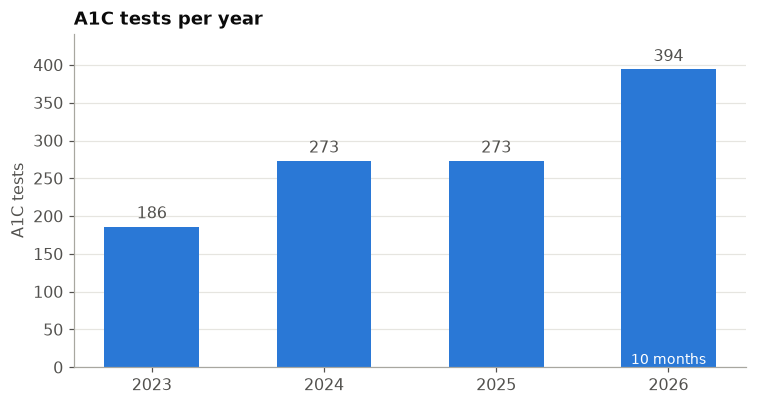

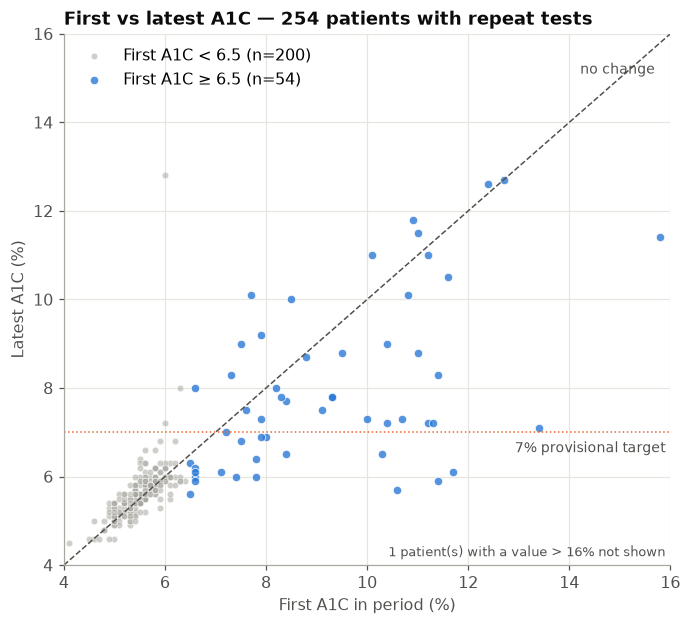

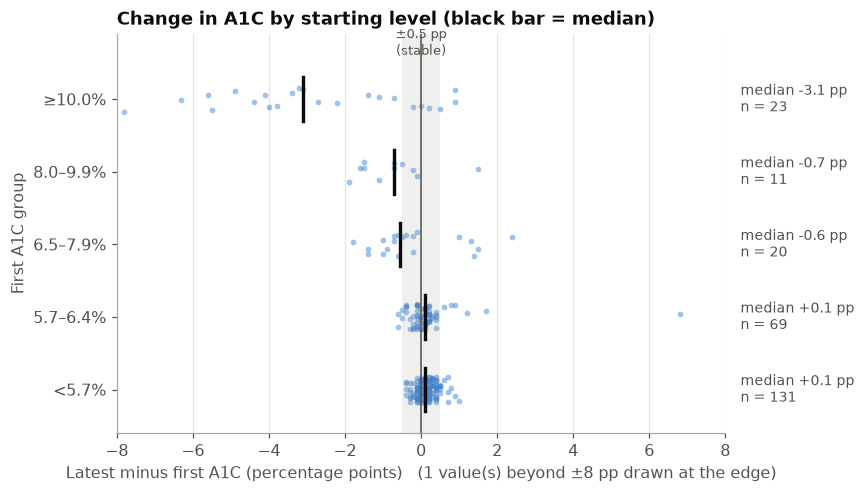

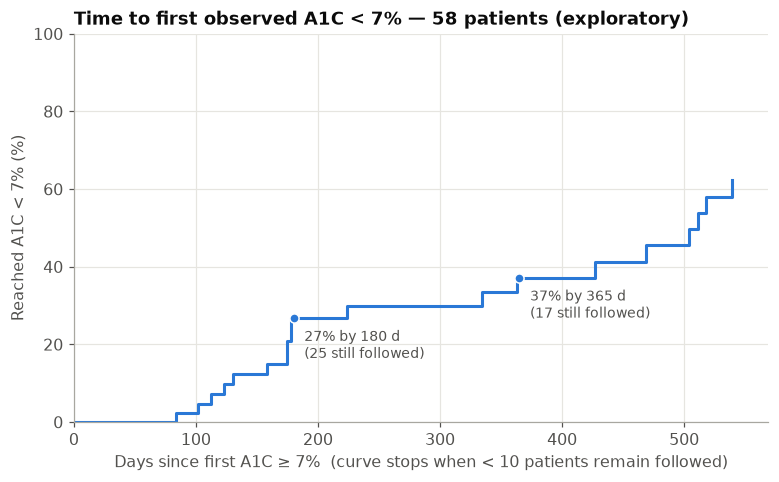

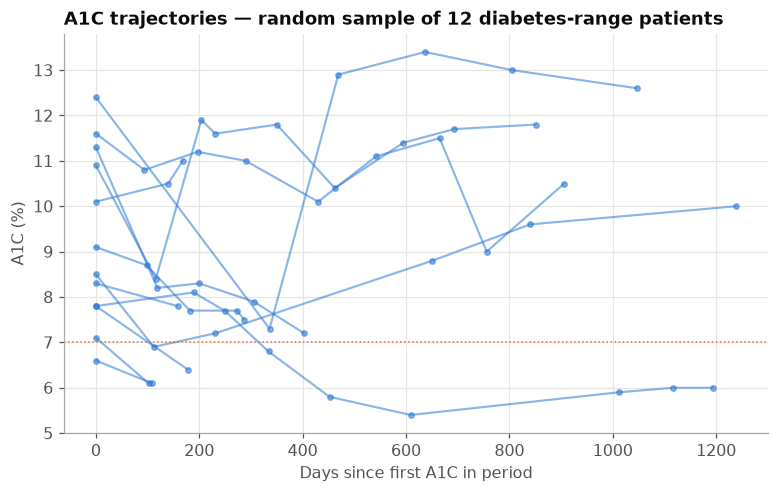

In [12]:
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / name, dpi=200)
    plt.show()

# 1. Annual testing volume
fig, ax = plt.subplots(figsize=(7, 3.8))
x = volume.index.astype(str)
bars = ax.bar(x, volume["a1c_tests"], width=0.55, color=BLUE)
ax.bar_label(bars, labels=[f"{n:,}" for n in volume["a1c_tests"]], padding=3, color=INK_2)
for i, (y, m) in enumerate(volume["months_covered"].items()):
    if m < 11.5:
        ax.text(i, 0, f"{m:.0f} months", ha="center", va="bottom", color="white", fontsize=9)
ax.set(ylabel="A1C tests", title="A1C tests per year")
ax.grid(axis="x", visible=False)
ax.margins(y=0.12)
finish(fig, "01_tests_per_year.png")

# 2. First vs latest (paired), diabetes-range cohort highlighted
fig, ax = plt.subplots(figsize=(6.4, 5.8))
other = paired[~paired["diabetes_range_at_baseline"]]
ax.scatter(other["baseline_a1c"], other["latest_a1c"], s=18, color=MUTED, alpha=.55,
           edgecolor="white", linewidth=.5, label=f"First A1C < {DIABETES_RANGE_THRESHOLD} (n={len(other)})")
ax.scatter(dm_paired["baseline_a1c"], dm_paired["latest_a1c"], s=30, color=BLUE, alpha=.8,
           edgecolor="white", linewidth=.6, label=f"First A1C ≥ {DIABETES_RANGE_THRESHOLD} (n={len(dm_paired)})")
lo, hi = 4, 16
off = paired[(paired[["baseline_a1c", "latest_a1c"]] > hi).any(axis=1)]
ax.plot([lo, hi], [lo, hi], "--", color=INK_2, linewidth=1)
ax.text(hi - .3, hi - .9, "no change", color=INK_2, ha="right", fontsize=9)
ax.axhline(threshold, color=ORANGE, linewidth=1, linestyle=":")
ax.text(hi - .1, threshold - .45, f"{threshold:g}% provisional target", color=INK_2, fontsize=9, ha="right")
if len(off):
    ax.text(hi - .1, lo + .2, f"{len(off)} patient(s) with a value > {hi}% not shown", color=INK_2,
            fontsize=8.5, ha="right")
ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="First A1C in period (%)", ylabel="Latest A1C (%)",
       title=f"First vs latest A1C — {len(paired):,} patients with repeat tests")
ax.legend(loc="upper left")
finish(fig, "02_first_vs_latest.png")

# 3. Change by starting group (strip + median)
groups = [g for g in BASELINE_LABELS if (paired["baseline_group"] == g).any()]
XMIN, XMAX = -8, 8
fig, ax = plt.subplots(figsize=(8, 4.6))
rng = np.random.default_rng(7)
n_clipped = 0
for i, g in enumerate(groups):
    vals = paired.loc[paired["baseline_group"] == g, "change_pp"]
    shown = vals.clip(XMIN + .2, XMAX - .2)
    n_clipped += int((shown != vals).sum())
    ax.scatter(shown, i + rng.uniform(-.18, .18, len(vals)), s=14, color=BLUE, alpha=.45, linewidth=0)
    ax.plot([vals.median()] * 2, [i - .3, i + .3], color=INK, linewidth=2.2)
    ax.text(XMAX + .4, i, f"median {vals.median():+.1f} pp\nn = {len(vals)}", va="center",
            fontsize=9, color=INK_2)
ax.axvspan(-tol, tol, color=MUTED, alpha=.18, linewidth=0)
ax.axvline(0, color=INK_2, linewidth=1)
ax.text(0, len(groups) - .45, f"±{tol:g} pp\n(stable)", ha="center", va="bottom", fontsize=8.5, color=INK_2)
ax.set_yticks(range(len(groups)), [f"{g}%" for g in groups])
ax.set_ylim(-.6, len(groups) - .1)
ax.set_xlim(XMIN, XMAX)
note = f"   ({n_clipped} value(s) beyond ±{XMAX} pp drawn at the edge)" if n_clipped else ""
ax.set(xlabel="Latest minus first A1C (percentage points)" + note, ylabel="First A1C group",
       title="Change in A1C by starting level (black bar = median)")
ax.grid(axis="y", visible=False)
finish(fig, "03_change_by_starting_level.png")

# 4. Time to first observed control (Kaplan–Meier, exploratory)
# Truncate where fewer than MIN_AT_RISK patients remain: the tail estimate is unstable.
MIN_AT_RISK = 10
t_all = time_to_control["time_days"]
cutoff = max(d for d in range(0, int(t_all.max()) + 1) if t_all.ge(d).sum() >= MIN_AT_RISK)
km_plot = pd.concat([km[km["days"].le(cutoff)],
                     pd.DataFrame({"days": [cutoff], "cumulative_pct_reached_control": [km_at(cutoff)]})])
fig, ax = plt.subplots(figsize=(7.2, 4.5))
ax.step(km_plot["days"], km_plot["cumulative_pct_reached_control"], where="post", color=BLUE, linewidth=2)
for d in (180, 365, 730):
    if d <= cutoff:
        ax.plot(d, km_at(d), "o", color=BLUE, markersize=6, markeredgecolor="white")
        ax.annotate(f"{km_at(d):.0f}% by {d} d\n({at_risk_at(d)} still followed)", (d, km_at(d)),
                    textcoords="offset points", xytext=(7, -26), fontsize=9, color=INK_2)
ax.set(xlim=(0, cutoff + 30), ylim=(0, 100),
       xlabel=f"Days since first A1C ≥ {threshold:g}%  (curve stops when < {MIN_AT_RISK} patients remain followed)",
       ylabel=f"Reached A1C < {threshold:g}% (%)",
       title=f"Time to first observed A1C < {threshold:g}% — {n_initial} patients (exploratory)")
finish(fig, "04_time_to_control.png")

# 5. Trajectories, diabetes-range sample
sample_ids = dm_paired.sample(n=min(12, len(dm_paired)), random_state=42).index
traj = clean[clean["patient_id"].isin(sample_ids)].join(patients[["baseline_date"]], on="patient_id")
traj["elapsed_days"] = (traj["date"] - traj["baseline_date"]).dt.days
fig, ax = plt.subplots(figsize=(7.2, 4.6))
for _, line in traj.groupby("patient_id"):
    ax.plot(line["elapsed_days"], line["a1c"], color=BLUE, alpha=.55, linewidth=1.4,
            marker="o", markersize=3.5)
ax.axhline(threshold, color=ORANGE, linewidth=1, linestyle=":")
ax.set(xlabel="Days since first A1C in period", ylabel="A1C (%)",
       title=f"A1C trajectories — random sample of {len(sample_ids)} diabetes-range patients")
finish(fig, "05_example_trajectories.png")

## 11. Save aggregate outputs and settings
Aggregate CSVs and the settings record go to `outputs/5.02a/`. Row-level files stay off unless `SAVE_ROW_LEVEL_FILES = True` (they contain account numbers and dates).

In [13]:
aggregate_outputs = {
    "label_audit": label_audit, "cleaning_counts": cleaning_counts, "testing_volume": volume,
    "tests_per_patient": tests_per_patient_table, "coverage": coverage_table,
    "baseline_distribution": baseline_distribution, "descriptive_change": descriptive,
    "change_by_baseline_group": baseline_comparison, "group_transitions": transition,
    "control_metrics": control_metrics, "prediabetes_progression": prediabetes_progression,
    "repeat_testing": repeat_testing, "km_time_to_control": km,
}
if COMPARE_FILE.exists():
    aggregate_outputs["date_range_check_vs_502b"] = date_check
for name, table in aggregate_outputs.items():
    table.to_csv(OUTPUT_DIR / f"{name}.csv")
settings = {
    "source_filename": INPUT_FILE.name, "compare_filename": COMPARE_FILE.name,
    "start_date": START_DATE, "end_date": END_DATE, "scope": scope,
    "verified_A1C_labels": sorted(A1C_LABELS), "units_confirmed_percent": UNITS_CONFIRMED_PERCENT,
    "settings_are_provisional": SETTINGS_ARE_PROVISIONAL,
    "prediabetes_threshold": PREDIABETES_THRESHOLD, "diabetes_range_threshold": DIABETES_RANGE_THRESHOLD,
    "control_threshold": CONTROL_THRESHOLD, "control_operator": CONTROL_OPERATOR,
    "stability_tolerance_pp": STABILITY_TOLERANCE_PP, "baseline_bins": BASELINE_BINS,
    "baseline_labels": BASELINE_LABELS, "followup_window_days": FOLLOWUP_WINDOW_DAYS,
    "collapse_identical_duplicates": COLLAPSE_IDENTICAL_DUPLICATES,
    "manual_exclusion_reason": EXCLUSION_REASON, "manual_exclude_source_rows": MANUAL_EXCLUDE_ROWS,
    "approved_keep_duplicate_source_rows": APPROVED_KEEP_DUPLICATE_ROWS, "export_notes": EXPORT_NOTES,
}
(OUTPUT_DIR / "methodology_settings.json").write_text(json.dumps(settings, indent=2, default=str), encoding="utf-8")
if SAVE_ROW_LEVEL_FILES:
    clean.to_csv(OUTPUT_DIR / "PRIVATE_clean_measurements.csv", index=False)
    review_log.to_csv(OUTPUT_DIR / "PRIVATE_rows_for_review.csv", index=False)
    patients.to_csv(OUTPUT_DIR / "PRIVATE_patient_summary.csv")
    time_to_control.to_csv(OUTPUT_DIR / "PRIVATE_time_to_control.csv")
print("Saved to:", OUTPUT_DIR.resolve())

Saved to: C:\Users\isaia\workspace\biokind\free_clinic_of_powhatan\clinic_a1c\outputs\5.02a


## 12. Checkpoint
CLEANING PROGRESS
Imported 55,364 report rows from 5.02a covering 466 lab attributes; 1,147 rows matched the
verified A1C attributes (Hemoglobin A1C / Hemoglobin A1c). Retained 1,126 A1C results from 519 patients,
collected 2023-01-05 to 2026-11-12. Set aside 21 rows: missing or non plain numeric result (4), identical same day copy (17).
The date window matches 5.02b (both start January 2023); 5.02b is the >=10% subset of the same data.

METHOD
Baseline is each patient's first A1C in the period; follow-up is their latest. Change = latest - first, in percentage points.
254 patients have >=2 distinct test dates (median follow-up 412 days).
Starting-level groups, the 6.5% diabetes-range cutpoint, the 7.0% control threshold and the ±0.5 pp tolerance are provisional ADA-based defaults, pending clinic approval.

PRELIMINARY FINDINGS
- Testing: 1,126 A1C tests; median 175 days between repeat tests; 51.1% of patients were tested only once.
- Starting levels: 62.4% of patients started <5.7%, 24.7% at 5.7–6.4%,
  and 67 (12.9%) at >=6.5% (diabetes-range cohort).
- Diabetes-range cohort with repeat tests (n=54): median A1C 8.9% -> 7.4%,
  median change -0.8 pp; 63% decreased >0.5 pp, 22% stable, 15% increased.
- Control: 31% of the diabetes-range cohort had a latest A1C < 7%
  (35% among those with repeat tests). Of 58 patients whose first A1C was >= 7%,
  23 later had a result < 7%; 11 had no later A1C at all.
  Exploratory Kaplan-Meier: about 37% reached < 7% within a year
  (only 17 patients were still being followed at 1 year, so treat this as rough).
- Prediabetes range (n=69 with repeat tests): 13% later had a result >=6.5%;
  12% had a latest result <5.7%.
- Repeat testing: 71% of the diabetes-range cohort (with time to observe it) were re-tested within
  183 days; 11% were never re-tested in the period.

LIMITATIONS
Lab extract only: diagnosis, medications and visits are unknown, so the diabetes-range cohort is a lab-based proxy.
Patients without any A1C are invisible. Baseline is not care start; follow-up length varies; patients who start high
improve partly through regression to the mean. Non-numeric results and >15.0% values need source review.
Nothing here establishes that clinic care caused the changes.